# 23CSE301 – Lab Session 10 (RAVDESS Speech Emotion Recognition)
**Stacking, Correlation Analysis and PCA**

- A1: Stacking Classifier with different meta-models
- A2: Feature correlation analysis + heatmap
- A3: PCA (99% variance) and performance comparison

Dataset: RAVDESS (8 emotions). Features are extracted from the .wav files with librosa (cached to a CSV so extraction runs only once). If you already have a features CSV from earlier labs, set `FEATURES_CSV` to it and make sure it has an `emotion` column (and optionally `actor`).

In [5]:
# ---------------- Configuration ----------------
!pip install -q librosa soundfile tqdm
AUDIO_DIR    = "ravdess"   # <-- folder containing Actor_01 ... Actor_24 (searched recursively)
FEATURES_CSV = "ravdess_features.csv"        # cache file (created automatically if missing)
TARGET_COL   = "emotion"
TASK         = "classification"
TEST_SIZE    = 0.2
RANDOM_STATE = 42
VARIANCE_TO_RETAIN = 0.99
SAMPLE_RATE  = 22050

In [6]:
import warnings
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              AdaBoostClassifier, AdaBoostRegressor,
                              GradientBoostingClassifier, GradientBoostingRegressor,
                              StackingClassifier, StackingRegressor)
from sklearn.svm import SVC, SVR
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             mean_squared_error, mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")

# =====================================================================
#                       ALL FUNCTIONS (single block)
#        (no print statements inside functions – prints are in main)
# =====================================================================

def load_dataset(path, target_col):
    """Load csv/xlsx file. Falls back to a sklearn demo dataset if file is missing.
    Returns (dataframe, target_col_name, used_demo_flag)."""
    if os.path.exists(path):
        df = pd.read_excel(path) if path.lower().endswith((".xlsx", ".xls")) else pd.read_csv(path)
        return df, target_col, False
    from sklearn.datasets import load_breast_cancer
    demo = load_breast_cancer(as_frame=True).frame
    return demo, "target", True


def detect_task(target_series, task="auto"):
    """Decide whether the problem is classification or regression."""
    if task != "auto":
        return task
    is_numeric = pd.api.types.is_numeric_dtype(target_series)
    few_unique = target_series.nunique() <= max(10, int(0.05 * len(target_series)))
    return "classification" if (not is_numeric or few_unique) else "regression"


def prepare_features(df, target_col, task):
    """Separate X / y, one-hot encode categoricals, impute missing values.
    Returns X (DataFrame), y (array), class_names (or None)."""
    df = df.dropna(subset=[target_col]).copy()
    y_raw = df[target_col]
    X = df.drop(columns=[target_col])
    # drop columns that are completely empty or identifiers with unique value per row
    X = X.dropna(axis=1, how="all")
    X = pd.get_dummies(X, drop_first=True).astype(float)
    X = X.loc[:, X.nunique() > 1]                      # remove constant columns
    X = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X), columns=X.columns)
    if task == "classification":
        encoder = LabelEncoder()
        y = encoder.fit_transform(y_raw.astype(str))
        return X, y, list(encoder.classes_)
    return X, y_raw.values.astype(float), None


def split_and_scale(X, y, task, test_size, random_state):
    """Train/test split followed by standardisation (fit on train only)."""
    strat = y if task == "classification" else None
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=test_size,
                                              random_state=random_state, stratify=strat)
    scaler = StandardScaler().fit(X_tr)
    return scaler.transform(X_tr), scaler.transform(X_te), y_tr, y_te


def get_base_models(task, random_state=42):
    """Dictionary of base models already implemented in earlier labs."""
    if task == "classification":
        return {
            "LogisticRegression": LogisticRegression(max_iter=2000),
            "KNN": KNeighborsClassifier(),
            "DecisionTree": DecisionTreeClassifier(random_state=random_state),
            "RandomForest": RandomForestClassifier(random_state=random_state),
            "AdaBoost": AdaBoostClassifier(random_state=random_state),
            "SVM": SVC(random_state=random_state),
            "NaiveBayes": GaussianNB(),
            "MLP": MLPClassifier(max_iter=1000, random_state=random_state),
        }
    return {
        "LinearRegression": LinearRegression(),
        "KNN": KNeighborsRegressor(),
        "DecisionTree": DecisionTreeRegressor(random_state=random_state),
        "RandomForest": RandomForestRegressor(random_state=random_state),
        "AdaBoost": AdaBoostRegressor(random_state=random_state),
        "SVR": SVR(),
        "MLP": MLPRegressor(max_iter=1000, random_state=random_state),
    }


def get_meta_models(task, random_state=42):
    """Different final_estimators (meta-models) to experiment with."""
    if task == "classification":
        return {
            "LogisticRegression": LogisticRegression(max_iter=2000),
            "DecisionTree": DecisionTreeClassifier(max_depth=5, random_state=random_state),
            "RandomForest": RandomForestClassifier(random_state=random_state),
            "GradientBoosting": GradientBoostingClassifier(random_state=random_state),
            "SVM": SVC(random_state=random_state),
            "KNN": KNeighborsClassifier(),
        }
    return {
        "LinearRegression": LinearRegression(),
        "Ridge": Ridge(alpha=1.0),
        "DecisionTree": DecisionTreeRegressor(max_depth=5, random_state=random_state),
        "RandomForest": RandomForestRegressor(random_state=random_state),
        "GradientBoosting": GradientBoostingRegressor(random_state=random_state),
        "SVR": SVR(),
    }


def build_stacking_model(task, base_models, meta_model, cv=5):
    """Build StackingClassifier / StackingRegressor from base models + final_estimator."""
    estimators = list(base_models.items())
    if task == "classification":
        return StackingClassifier(estimators=estimators, final_estimator=meta_model, cv=cv, n_jobs=-1)
    return StackingRegressor(estimators=estimators, final_estimator=meta_model, cv=cv, n_jobs=-1)


def compute_metrics(task, y_true, y_pred):
    """Return metrics dictionary for the given task."""
    if task == "classification":
        return {"Accuracy": accuracy_score(y_true, y_pred),
                "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
                "Recall": recall_score(y_true, y_pred, average="weighted", zero_division=0),
                "F1": f1_score(y_true, y_pred, average="weighted", zero_division=0)}
    mse = mean_squared_error(y_true, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(y_true, y_pred), "R2": r2_score(y_true, y_pred)}


def fit_and_evaluate(task, model, X_train, X_test, y_train, y_test):
    """Fit one model; return train metrics and test metrics (prefixed)."""
    model.fit(X_train, y_train)
    out = {}
    for prefix, Xs, ys in (("Train", X_train, y_train), ("Test", X_test, y_test)):
        for name, val in compute_metrics(task, ys, model.predict(Xs)).items():
            out[f"{prefix} {name}"] = val
    return out


def evaluate_models(task, models, X_train, X_test, y_train, y_test):
    """Evaluate a dict of models and return a results DataFrame."""
    rows = {name: fit_and_evaluate(task, m, X_train, X_test, y_train, y_test)
            for name, m in models.items()}
    return pd.DataFrame(rows).T.round(4)


def evaluate_stacking_variants(task, base_models, meta_models, X_train, X_test, y_train, y_test):
    """A1: run stacking with every meta-model and return results DataFrame."""
    rows = {}
    for meta_name, meta in meta_models.items():
        stack = build_stacking_model(task, base_models, meta)
        rows[f"Stack[{meta_name}]"] = fit_and_evaluate(task, stack, X_train, X_test, y_train, y_test)
    return pd.DataFrame(rows).T.round(4)


def compute_correlation(X, y, target_name):
    """A2: correlation matrix of features including the target."""
    data = X.copy()
    data[target_name] = y
    return data.corr()


def find_high_correlation_pairs(corr_matrix, threshold=0.8):
    """List feature pairs whose |correlation| exceeds threshold."""
    cols = corr_matrix.columns
    pairs = [(cols[i], cols[j], corr_matrix.iloc[i, j])
             for i in range(len(cols)) for j in range(i + 1, len(cols))
             if abs(corr_matrix.iloc[i, j]) >= threshold]
    return pd.DataFrame(pairs, columns=["Feature 1", "Feature 2", "Correlation"]) \
             .sort_values("Correlation", key=abs, ascending=False).reset_index(drop=True)


def plot_heatmap(corr_matrix, title="Feature Correlation Heatmap"):
    """Draw heatmap of correlation matrix."""
    n = len(corr_matrix)
    plt.figure(figsize=(min(0.6 * n + 4, 22), min(0.5 * n + 3, 18)))
    sns.heatmap(corr_matrix, cmap="coolwarm", center=0, annot=(n <= 15),
                fmt=".2f", linewidths=0.3 if n <= 30 else 0)
    plt.title(title)
    plt.tight_layout()
    plt.show()


def pca_reduce(X_train, X_test, variance_to_retain=0.99):
    """A3: PCA keeping smallest number of components whose cumulative variance >= threshold.
    Returns transformed train/test, number of components and cumulative variance array."""
    full_pca = PCA().fit(X_train)
    cumulative = np.cumsum(full_pca.explained_variance_ratio_)
    n_components = int(np.argmax(cumulative >= variance_to_retain) + 1)
    pca = PCA(n_components=n_components).fit(X_train)
    return pca.transform(X_train), pca.transform(X_test), n_components, cumulative


def plot_cumulative_variance(cumulative, n_components, threshold):
    """Plot cumulative explained variance curve."""
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o", markersize=3)
    plt.axhline(threshold, color="r", linestyle="--", label=f"{threshold:.0%} variance")
    plt.axvline(n_components, color="g", linestyle="--", label=f"{n_components} components")
    plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance")
    plt.title("PCA – Cumulative Explained Variance"); plt.legend(); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()


def compare_results(original_df, pca_df, metric):
    """Side-by-side comparison of one metric (original vs PCA)."""
    cmp = pd.DataFrame({f"Original {metric}": original_df[metric],
                        f"PCA {metric}": pca_df[metric]})
    cmp["Difference (PCA - Original)"] = (cmp.iloc[:, 1] - cmp.iloc[:, 0]).round(4)
    return cmp

# ------------------ RAVDESS-specific functions ------------------
import glob
import librosa

EMOTION_MAP = {"01": "neutral", "02": "calm", "03": "happy", "04": "sad",
               "05": "angry", "06": "fearful", "07": "disgust", "08": "surprised"}


def parse_ravdess_filename(file_path):
    """RAVDESS name: modality-channel-emotion-intensity-statement-repetition-actor.wav"""
    parts = os.path.splitext(os.path.basename(file_path))[0].split("-")
    return {"emotion": EMOTION_MAP[parts[2]], "actor": int(parts[6])}


def extract_audio_features(file_path, sample_rate=22050):
    """Extract a fixed-length feature vector (MFCC, chroma, contrast, spectral, ZCR, RMS)."""
    signal, sr = librosa.load(file_path, sr=sample_rate, duration=3.0, offset=0.5)
    feats = {}
    mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40)
    for i in range(mfcc.shape[0]):
        feats[f"mfcc{i+1}_mean"] = mfcc[i].mean()
        feats[f"mfcc{i+1}_std"] = mfcc[i].std()
    chroma = librosa.feature.chroma_stft(y=signal, sr=sr)
    for i in range(chroma.shape[0]):
        feats[f"chroma{i+1}_mean"] = chroma[i].mean()
    contrast = librosa.feature.spectral_contrast(y=signal, sr=sr)
    for i in range(contrast.shape[0]):
        feats[f"contrast{i+1}_mean"] = contrast[i].mean()
    feats["zcr_mean"] = librosa.feature.zero_crossing_rate(signal).mean()
    feats["rms_mean"] = librosa.feature.rms(y=signal).mean()
    feats["centroid_mean"] = librosa.feature.spectral_centroid(y=signal, sr=sr).mean()
    feats["bandwidth_mean"] = librosa.feature.spectral_bandwidth(y=signal, sr=sr).mean()
    feats["rolloff_mean"] = librosa.feature.spectral_rolloff(y=signal, sr=sr).mean()
    return feats


def find_audio_files(audio_dir):
    """Recursively list all .wav files."""
    return sorted(glob.glob(os.path.join(audio_dir, "**", "*.wav"), recursive=True))


def assemble_feature_table(file_paths, feature_rows):
    """Combine labels (from file names) and extracted features into one DataFrame."""
    meta = pd.DataFrame([parse_ravdess_filename(p) for p in file_paths])
    return pd.concat([pd.DataFrame(feature_rows), meta], axis=1)


## Load data & preprocessing

In [7]:
from tqdm.auto import tqdm

# ---- Build (or load cached) feature table ----
if os.path.exists(FEATURES_CSV):
    df = pd.read_csv(FEATURES_CSV)
    print("Loaded cached features from", FEATURES_CSV)
else:
    audio_files = find_audio_files(AUDIO_DIR)
    print("Audio files found:", len(audio_files))
    assert len(audio_files) > 0, "No .wav files found - check AUDIO_DIR"
    feature_rows = [extract_audio_features(p, SAMPLE_RATE) for p in tqdm(audio_files)]
    df = assemble_feature_table(audio_files, feature_rows)
    df.to_csv(FEATURES_CSV, index=False)
    print("Features saved to", FEATURES_CSV)

# actor id is metadata, not a feature -> drop before modelling
model_df = df.drop(columns=[col for col in ["actor"] if col in df.columns])

task = detect_task(model_df[TARGET_COL], TASK)
X, y, class_names = prepare_features(model_df, TARGET_COL, task)
X_train, X_test, y_train, y_test = split_and_scale(X, y, task, TEST_SIZE, RANDOM_STATE)

print("Task               :", task)
print("Classes            :", class_names)
print("Dataset shape      :", df.shape)
print("Features           :", X.shape[1])
print("Train / Test sizes :", X_train.shape[0], "/", X_test.shape[0])

Audio files found: 1440


  0%|          | 0/1440 [00:00<?, ?it/s]

Task was destroyed but it is pending!
task: <Task pending name='Task-75' coro=<_async_in_context.<locals>.run_in_context() done, defined at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/utils.py:57> wait_for=<Task pending name='Task-76' coro=<Kernel.shell_main() running at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/zmq/eventloop/zmqstream.py:563]>
Task was destroyed but it is pending!
task: <Task pending name='Task-76' coro=<Kernel.shell_main() running at /Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/ipykernel/kernelbase.py:597> cb=[Task.task_wakeup()]>


Features saved to ravdess_features.csv
Task               : classification
Classes            : ['angry', 'calm', 'disgust', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
Dataset shape      : (1440, 106)
Features           : 104
Train / Test sizes : 1152 / 288


## A1. Stacking Classifier / Regressor with various meta-models

In [8]:
base_models = get_base_models(task, RANDOM_STATE)
meta_models = get_meta_models(task, RANDOM_STATE)

# Individual base-model performance (for reference)
base_results = evaluate_models(task, base_models, X_train, X_test, y_train, y_test)
print("Base model performance:")
display(base_results)

# Stacking with different final_estimators
stack_results = evaluate_stacking_variants(task, base_models, meta_models,
                                           X_train, X_test, y_train, y_test)
print("\nStacking performance with different meta-models:")
display(stack_results)

key_metric = "Test Accuracy" if task == "classification" else "Test R2"
best_meta = stack_results[key_metric].idxmax()
print(f"\nBest meta-model by {key_metric}: {best_meta} ({stack_results[key_metric].max():.4f})")

Base model performance:


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
LogisticRegression,0.8542,0.8546,0.8542,0.8540,0.5868,0.5924,0.5868,0.5889
KNN,0.8021,0.8080,0.8021,0.8005,0.6007,0.6150,0.6007,0.6016
DecisionTree,1.0000,1.0000,1.0000,1.0000,0.4028,0.4038,0.4028,0.4012
RandomForest,1.0000,1.0000,1.0000,1.0000,0.5972,0.6009,0.5972,0.5886
AdaBoost,0.3967,0.3998,0.3967,0.3800,0.3542,0.3381,0.3542,0.3357
SVM,0.8837,0.8882,0.8837,0.8838,0.6389,0.6400,0.6389,0.6317
NaiveBayes,0.4253,0.4697,0.4253,0.4186,0.3333,0.3870,0.3333,0.3421
MLP,1.0000,1.0000,1.0000,1.0000,0.6979,0.6953,0.6979,0.6945



Stacking performance with different meta-models:


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
Stack[LogisticRegression],0.9983,0.9983,0.9983,0.9983,0.7465,0.7484,0.7465,0.7400
Stack[DecisionTree],0.7769,0.6958,0.7769,0.7200,0.5833,0.5631,0.5833,0.5530
Stack[RandomForest],1.0000,1.0000,1.0000,1.0000,0.7361,0.7401,0.7361,0.7302
Stack[GradientBoosting],0.9974,0.9974,0.9974,0.9974,0.7118,0.7104,0.7118,0.7074
Stack[SVM],0.9141,0.9177,0.9141,0.9139,0.6806,0.6803,0.6806,0.6664
Stack[KNN],0.8620,0.8655,0.8620,0.8599,0.6389,0.6420,0.6389,0.6258



Best meta-model by Test Accuracy: Stack[LogisticRegression] (0.7465)


## A2. Feature correlation analysis & heatmap

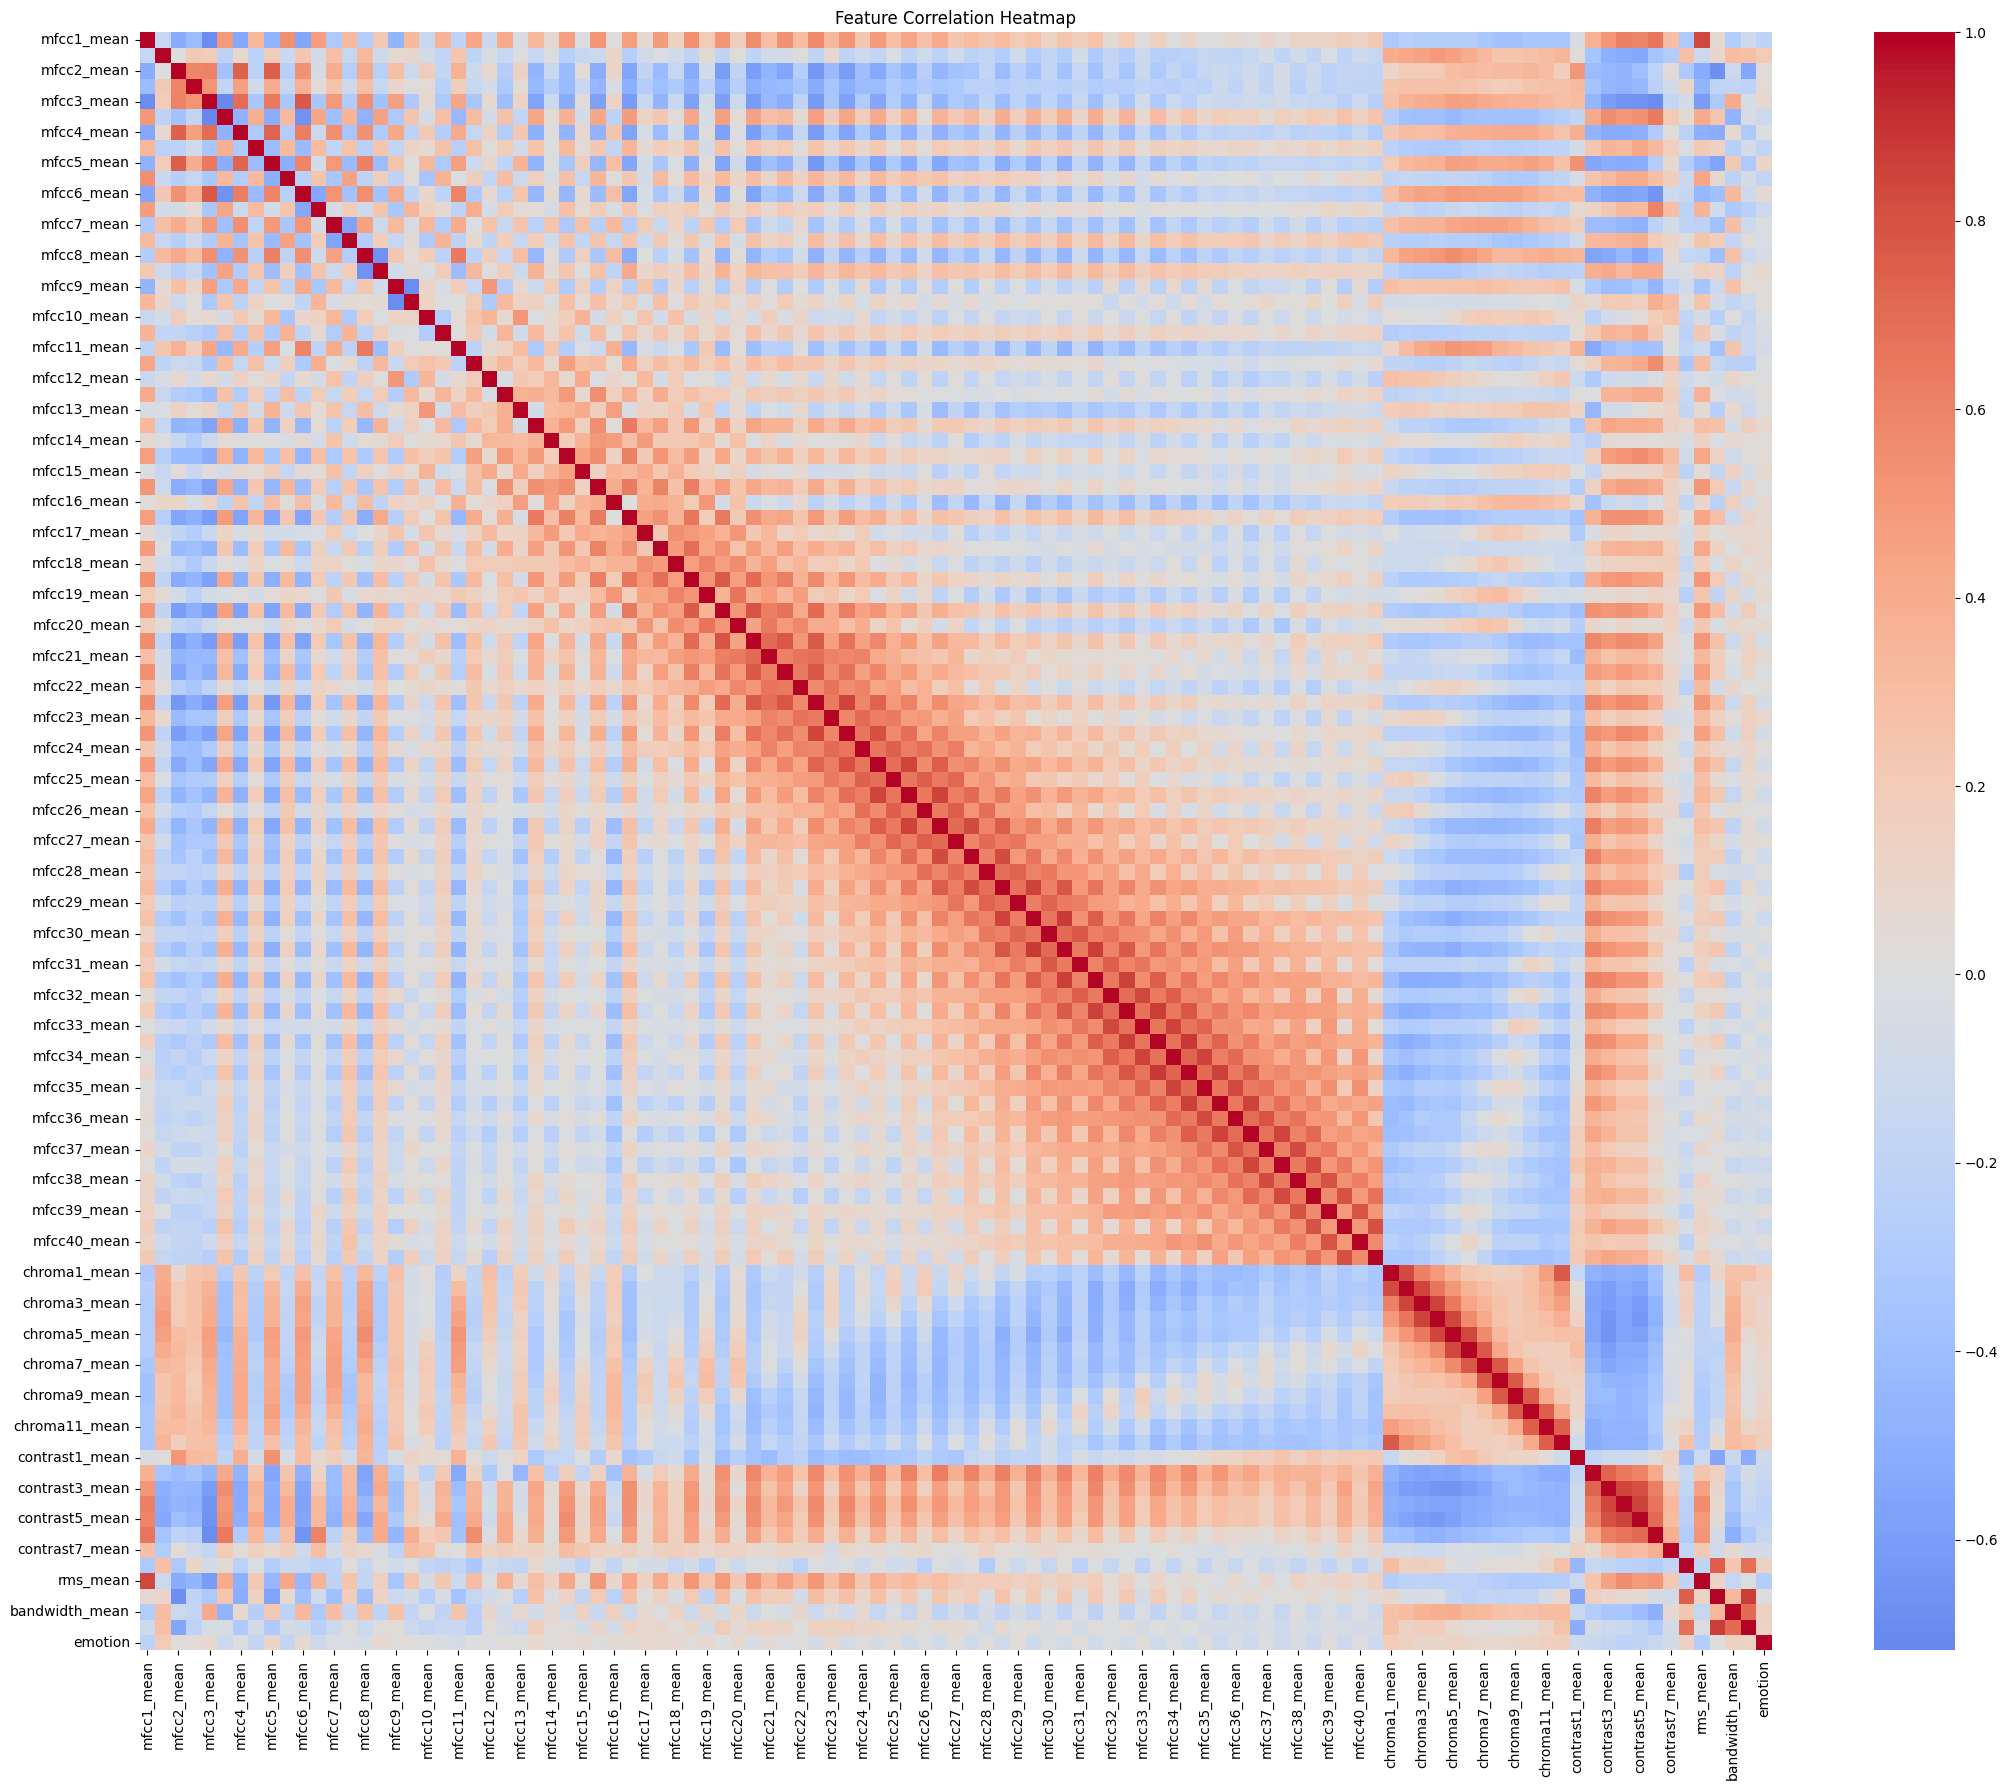

Feature pairs with |correlation| >= 0.8: 32


,Feature 1,Feature 2,Correlation
0,mfcc33_std,mfcc34_std,0.881764
1,mfcc29_std,mfcc30_std,0.874068
2,mfcc30_std,mfcc31_std,0.871307
3,centroid_mean,rolloff_mean,0.869842
4,mfcc32_std,mfcc33_std,0.868961
5,mfcc34_std,mfcc35_std,0.864450
6,mfcc31_std,mfcc32_std,0.861338
7,mfcc28_std,mfcc29_std,0.857627
8,chroma3_mean,chroma4_mean,0.854675
9,mfcc35_std,mfcc36_std,0.853072



Top 10 features correlated with the target:


,|Correlation|
rms_mean,0.2713
mfcc1_mean,0.2251
contrast4_mean,0.2169
mfcc1_std,0.2036
contrast5_mean,0.2004
chroma1_mean,0.1867
mfcc4_std,0.1741
chroma12_mean,0.1738
mfcc5_std,0.1719
contrast3_mean,0.1679


In [9]:
corr_matrix = compute_correlation(X, y, TARGET_COL)
plot_heatmap(corr_matrix)

high_pairs = find_high_correlation_pairs(corr_matrix.drop(index=TARGET_COL, columns=TARGET_COL), threshold=0.8)
print(f"Feature pairs with |correlation| >= 0.8: {len(high_pairs)}")
display(high_pairs.head(15))

print("\nTop 10 features correlated with the target:")
display(corr_matrix[TARGET_COL].drop(TARGET_COL).abs().sort_values(ascending=False).head(10).round(4).to_frame("|Correlation|"))

## A3. PCA (99% variance) and model comparison

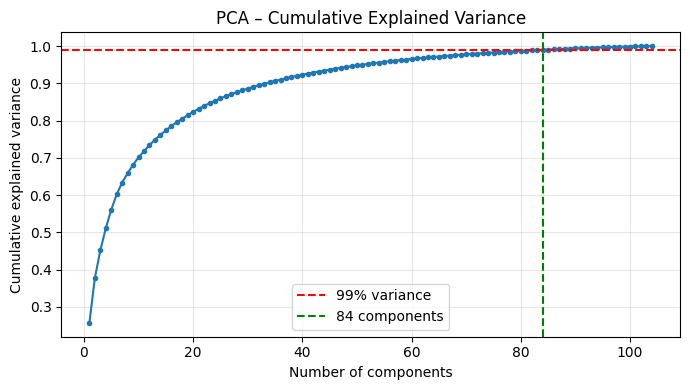

Original features: 104  ->  PCA components: 84

Base models on PCA-reduced features:


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
LogisticRegression,0.8186,0.8190,0.8186,0.8182,0.5903,0.5924,0.5903,0.5904
KNN,0.8003,0.8059,0.8003,0.7987,0.6076,0.6259,0.6076,0.6092
DecisionTree,1.0000,1.0000,1.0000,1.0000,0.3333,0.3395,0.3333,0.3352
RandomForest,1.0000,1.0000,1.0000,1.0000,0.5799,0.5762,0.5799,0.5651
AdaBoost,0.4045,0.4140,0.4045,0.4044,0.3264,0.3148,0.3264,0.3161
SVM,0.8785,0.8826,0.8785,0.8784,0.6319,0.6289,0.6319,0.6243
NaiveBayes,0.6623,0.6919,0.6623,0.6635,0.4965,0.5080,0.4965,0.4958
MLP,1.0000,1.0000,1.0000,1.0000,0.7049,0.7085,0.7049,0.7039



Stacking on PCA-reduced features:


,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1
Stack[LogisticRegression],0.9905,0.9907,0.9905,0.9905,0.7257,0.73,0.7257,0.7219


In [10]:
X_train_pca, X_test_pca, n_comp, cumulative = pca_reduce(X_train, X_test, VARIANCE_TO_RETAIN)
plot_cumulative_variance(cumulative, n_comp, VARIANCE_TO_RETAIN)
print(f"Original features: {X_train.shape[1]}  ->  PCA components: {n_comp}")

# Base models on PCA features
base_results_pca = evaluate_models(task, get_base_models(task, RANDOM_STATE),
                                   X_train_pca, X_test_pca, y_train, y_test)
print("\nBase models on PCA-reduced features:")
display(base_results_pca)

# Stacking (best meta-model) on PCA features
best_meta_name = best_meta.replace("Stack[", "").replace("]", "")
stack_pca = evaluate_stacking_variants(task, get_base_models(task, RANDOM_STATE),
                                       {best_meta_name: get_meta_models(task, RANDOM_STATE)[best_meta_name]},
                                       X_train_pca, X_test_pca, y_train, y_test)
print("\nStacking on PCA-reduced features:")
display(stack_pca)

In [11]:
# Comparison: original vs PCA
all_original = pd.concat([base_results, stack_results.loc[[best_meta]]])
all_pca = pd.concat([base_results_pca, stack_pca])

for metric in (["Test Accuracy", "Test F1"] if task == "classification" else ["Test RMSE", "Test R2"]):
    print(f"\nComparison – {metric}")
    display(compare_results(all_original, all_pca, metric))


Comparison – Test Accuracy


,Original Test Accuracy,PCA Test Accuracy,Difference (PCA - Original)
LogisticRegression,0.5868,0.5903,0.0035
KNN,0.6007,0.6076,0.0069
DecisionTree,0.4028,0.3333,-0.0695
RandomForest,0.5972,0.5799,-0.0173
AdaBoost,0.3542,0.3264,-0.0278
SVM,0.6389,0.6319,-0.0070
NaiveBayes,0.3333,0.4965,0.1632
MLP,0.6979,0.7049,0.0070
Stack[LogisticRegression],0.7465,0.7257,-0.0208



Comparison – Test F1


,Original Test F1,PCA Test F1,Difference (PCA - Original)
LogisticRegression,0.5889,0.5904,0.0015
KNN,0.6016,0.6092,0.0076
DecisionTree,0.4012,0.3352,-0.0660
RandomForest,0.5886,0.5651,-0.0235
AdaBoost,0.3357,0.3161,-0.0196
SVM,0.6317,0.6243,-0.0074
NaiveBayes,0.3421,0.4958,0.1537
MLP,0.6945,0.7039,0.0094
Stack[LogisticRegression],0.7400,0.7219,-0.0181


## Observations (fill after running)
- Which meta-model gave the best stacking result and by how much it beats the best single base model?
- Which features are highly correlated (A2)? Are they redundant?
- How many components retain 99% variance and how did accuracy / R² change vs original features?